# 05 — Model Experiments and Comparative Analysis

## Project: PlantLeafNet — Advanced Plant Disease Detection

### Objective
This notebook compares the performance of multiple deep learning models trained for plant disease classification using the PlantVillage dataset.

### Models evaluated
1. Custom CNN
2. Weighted Custom CNN
3. MobileNetV3-Large (Transfer Learning)
4. MobileNetV3-Large (Fine-Tuned)
5. EfficientNetV2-S (Transfer Learning)
6. EfficientNetV2-S (Fine-Tuned)

### Experimental objectives
- Compare training and validation performance.
- Analyse the effect of class weighting.
- Evaluate the impact of transfer learning and fine-tuning.
- Compare model complexity and training time.
- Identify the most suitable model for deployment.

### Important
All comparisons use previously recorded experimental results. No additional model training is performed in this notebook.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/PlantLeafNet")

MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

print("Project directory:", PROJECT_DIR)
print("Models directory:", MODEL_DIR)
print("Results directory:", RESULT_DIR)

Project directory: /content/drive/MyDrive/PlantLeafNet
Models directory: /content/drive/MyDrive/PlantLeafNet/models
Results directory: /content/drive/MyDrive/PlantLeafNet/results


In [4]:
print("Available result files:\n")

for file in sorted(RESULT_DIR.iterdir()):
    print(file.name)

Available result files:

cnn_baseline_history.csv
cnn_comparison.csv
efficientnet_finetuning_history.csv
efficientnet_test_classification_report.csv
efficientnet_test_confusion_matrix.csv
efficientnet_v2_s_history.csv
mobilenet_finetuning_history.csv
mobilenet_test_classification_report.csv
mobilenet_test_confusion_matrix.csv
mobilenet_training_history.csv
weighted_cnn_history.csv


In [5]:
history_files = {
    "CNN": "cnn_baseline_history.csv",
    "Weighted CNN": "weighted_cnn_history.csv",
    "MobileNetV3": "mobilenet_training_history.csv",
    "MobileNetV3 Fine-Tuned": "mobilenet_finetuning_history.csv",
    "EfficientNetV2-S": "efficientnet_v2_s_history.csv",
    "EfficientNetV2-S Fine-Tuned": "efficientnet_finetuning_history.csv"
}

histories = {}

for model_name, filename in history_files.items():
    file_path = RESULT_DIR / filename

    histories[model_name] = pd.read_csv(file_path)

    print(f"\n{model_name}")
    print(histories[model_name].head())


CNN
   Epoch  train_loss  train_accuracy  val_loss  val_accuracy
0      1    0.932338       72.401179  0.777976     75.669369
1      2    0.734528       77.911995  0.748812     75.951855
2      3    0.635249       80.717406  0.499884     84.782609
3      4    0.560164       82.901732  0.716387     77.462540
4      5    0.518734       83.883362  0.966231     70.289855

Weighted CNN
   Epoch  train_loss  train_accuracy  val_loss  val_accuracy
0      1    0.625692       79.988420  0.409951     86.710882
1      2    0.581831       81.272699  0.729420     77.094080
2      3    0.541486       82.693826  0.466510     83.407025
3      4    0.502421       83.462287  0.654424     79.906657
4      5    0.480153       84.283383  0.475102     83.738639

MobileNetV3
   Epoch  train_loss  train_accuracy  val_loss  val_accuracy
0      0    1.043336       91.157429  0.911135     94.755588
1      1    0.892791       95.791884  0.855171     96.855809
2      2    0.867442       96.560345  0.859253     96

In [7]:
comparison = []

for model_name, history in histories.items():

    best_epoch = history["val_acc"].idxmax()

    comparison.append({
        "Model": model_name,
        "Best Validation Accuracy (%)": history.loc[best_epoch, "val_acc"],
        "Best Epoch": best_epoch + 1,
        "Validation Loss": history.loc[best_epoch, "val_loss"]
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="Best Validation Accuracy (%)",
    ascending=False
)

comparison_df

KeyError: 'val_acc'

Note: These plots use recorded epoch order; MobileNet's history starts at epoch 0 while other histories start at epoch 1.

In [9]:
histories_clean = {}

for model_name, history in histories.items():

    df = history.copy()

    df = df.rename(columns={
        "train_accuracy": "train_acc",
        "val_accuracy": "val_acc"
    })

    histories_clean[model_name] = df

    print(model_name, "->", list(df.columns))

CNN -> ['Epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc']
Weighted CNN -> ['Epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc']
MobileNetV3 -> ['Epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc']
MobileNetV3 Fine-Tuned -> ['Epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc']
EfficientNetV2-S -> ['train_loss', 'train_acc', 'val_loss', 'val_acc']
EfficientNetV2-S Fine-Tuned -> ['train_loss', 'train_acc', 'val_loss', 'val_acc']


In [10]:
comparison = []

for model_name, history in histories_clean.items():

    best_epoch = history["val_acc"].idxmax()

    comparison.append({
        "Model": model_name,
        "Best Validation Accuracy (%)": history.loc[best_epoch, "val_acc"],
        "Best Epoch": int(history.loc[best_epoch, "Epoch"])
                      if "Epoch" in history.columns
                      else best_epoch + 1,
        "Validation Loss": history.loc[best_epoch, "val_loss"]
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="Best Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Best Validation Accuracy (%),Best Epoch,Validation Loss
0,MobileNetV3 Fine-Tuned,98.919184,2,0.764876
1,EfficientNetV2-S Fine-Tuned,98.526161,3,0.811354
2,MobileNetV3,97.334807,4,0.833728
3,EfficientNetV2-S,89.044461,5,1.145081
4,Weighted CNN,86.710882,1,0.409951
5,CNN,84.782609,3,0.499884


## Experimental Comparison and Findings

Six model configurations were evaluated for plant disease classification.

The custom CNN achieved a best validation accuracy of 84.78%, while the weighted CNN achieved 86.71%. These results established the baseline performance of models trained from scratch.

Transfer learning substantially improved performance. MobileNetV3-Large achieved 97.33% validation accuracy using feature extraction, while EfficientNetV2-S achieved 89.04%.

Selective fine-tuning further improved both architectures. MobileNetV3-Large reached 98.92%, and EfficientNetV2-S reached 98.53%.

MobileNetV3-Large Fine-Tuned achieved the highest validation accuracy among the evaluated configurations. It also has fewer parameters than EfficientNetV2-S, making it a promising candidate for deployment.

These findings suggest that pretrained visual representations and selective fine-tuning are highly effective for this PlantVillage classification task.

The results are specific to the experimental dataset and split. High PlantVillage accuracy alone does not establish reliable performance under real agricultural field conditions.

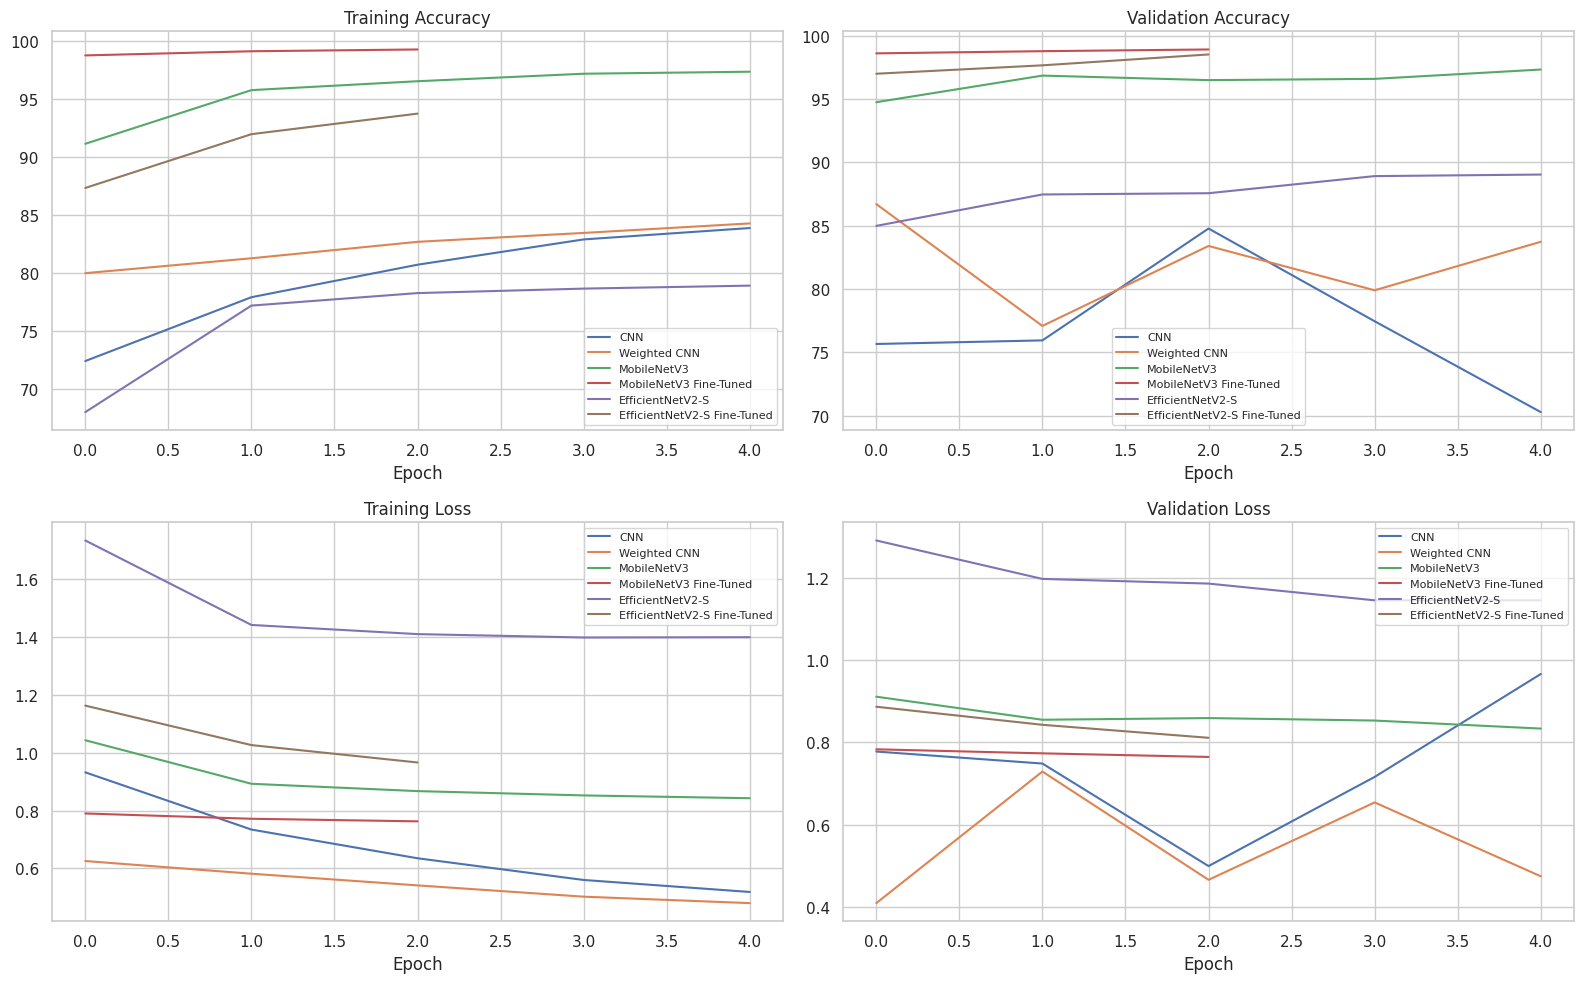

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for model_name, history in histories_clean.items():

    axes[0, 0].plot(
        history["train_acc"].values,
        label=model_name
    )

    axes[0, 1].plot(
        history["val_acc"].values,
        label=model_name
    )

    axes[1, 0].plot(
        history["train_loss"].values,
        label=model_name
    )

    axes[1, 1].plot(
        history["val_loss"].values,
        label=model_name
    )

axes[0, 0].set_title("Training Accuracy")
axes[0, 1].set_title("Validation Accuracy")
axes[1, 0].set_title("Training Loss")
axes[1, 1].set_title("Validation Loss")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
    ax.grid(True)

plt.tight_layout()
plt.show()

## Learning Curve Analysis

The learning curves reveal differences in optimization and generalization behaviour across the six experimental configurations.

### Custom CNN
The custom CNN showed increasing training accuracy but unstable validation accuracy. Its validation accuracy peaked at approximately 84.78% before declining to approximately 70.29% in the final epoch. The corresponding increase in validation loss suggests unstable generalization during the later training stage.

### Weighted CNN
Class-weighted training improved the best validation accuracy to approximately 86.71%. However, validation performance fluctuated across epochs, indicating that class weighting alone did not provide the same performance improvement as transfer learning.

### MobileNetV3-Large
Feature extraction achieved approximately 97.33% validation accuracy. Selective fine-tuning further improved this to approximately 98.92%. Training and validation performance remained consistently high.

### EfficientNetV2-S
Feature extraction achieved approximately 89.04% validation accuracy. After selective fine-tuning, validation accuracy increased to approximately 98.53%, while validation loss decreased across the three fine-tuning epochs.

### Overall observation
Transfer learning and selective fine-tuning substantially improved classification performance compared with the custom CNN baselines. MobileNetV3-Large Fine-Tuned achieved the highest validation accuracy among the evaluated configurations.

These results describe performance on the PlantVillage dataset and do not independently establish generalization to images captured in real agricultural environments.

In [12]:
model_complexity = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "Weighted CNN",
        "MobileNetV3-Large",
        "EfficientNetV2-S"
    ],
    "Total Parameters": [
        98598,
        98598,
        4250710,
        20226166
    ]
})

model_complexity["Parameters (Millions)"] = (
    model_complexity["Total Parameters"] / 1_000_000
)

model_complexity

,Model,Total Parameters,Parameters (Millions)
0,Custom CNN,98598,0.098598
1,Weighted CNN,98598,0.098598
2,MobileNetV3-Large,4250710,4.250710
3,EfficientNetV2-S,20226166,20.226166


## Model Complexity Analysis

The custom CNN and weighted CNN contain 98,598 parameters each because class weighting changes the loss calculation, not the network architecture.

MobileNetV3-Large contains 4.25 million parameters, whereas EfficientNetV2-S contains approximately 20.23 million parameters.

Despite its smaller architecture, fine-tuned MobileNetV3-Large achieved the highest validation accuracy of 98.92%, compared with 98.53% for fine-tuned EfficientNetV2-S.

Therefore, MobileNetV3-Large offers a promising balance between classification performance and model complexity for this project.

In [13]:
model_files = {
    "MobileNetV3-Large Fine-Tuned": MODEL_DIR / "best_mobilenet_finetuned.pth",
    "EfficientNetV2-S Fine-Tuned": MODEL_DIR / "best_efficientnet_finetuned.pth",
    "Custom CNN": MODEL_DIR / "best_cnn_baseline.pth",
    "Weighted CNN": MODEL_DIR / "best_weighted_cnn.pth"
}

size_results = []

for name, path in model_files.items():
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)

        size_results.append({
            "Model": name,
            "File Size (MB)": round(size_mb, 2)
        })
    else:
        print("File not found:", path.name)

size_df = pd.DataFrame(size_results)
size_df

,Model,File Size (MB)
0,MobileNetV3-Large Fine-Tuned,16.42
1,EfficientNetV2-S Fine-Tuned,78.03
2,Custom CNN,0.39
3,Weighted CNN,0.39


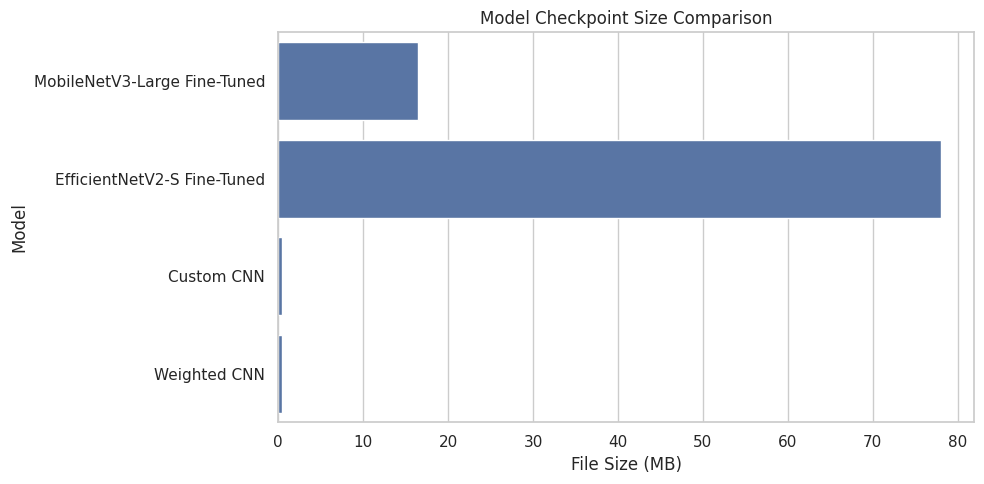

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=size_df,
    x="File Size (MB)",
    y="Model"
)

plt.title("Model Checkpoint Size Comparison")
plt.tight_layout()
plt.show()

In [15]:
comparison_df.to_csv(
    RESULT_DIR / "model_validation_comparison.csv",
    index=False
)

size_df.to_csv(
    RESULT_DIR / "model_checkpoint_sizes.csv",
    index=False
)

print("Model comparison results saved!")

Model comparison results saved!


## Final Experimental Conclusion

Six model configurations were compared using their training histories and validation performance.

MobileNetV3-Large Fine-Tuned achieved the highest validation accuracy of 98.92%, followed by EfficientNetV2-S Fine-Tuned at 98.53%.

The MobileNetV3-Large checkpoint occupied 16.42 MB, compared with 78.03 MB for EfficientNetV2-S.

Although EfficientNetV2-S achieved competitive classification performance, MobileNetV3-Large provided a better balance between validation accuracy and checkpoint size.

The experimental results therefore identify MobileNetV3-Large Fine-Tuned as the leading candidate for deployment.

Final test evaluation also supported this selection: MobileNetV3-Large achieved 98.89% test accuracy, while EfficientNetV2-S achieved 98.46%.

These results apply to the PlantVillage test distribution. Evaluation on independent field images is still necessary before making claims about real-world agricultural reliability.